In [1]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from dateutil.parser import parse
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

In [2]:
os.chdir(r"C:\Users\Carol lopes\OneDrive\Documents\time series")
data = pd.read_csv("RELIANCE.NS Prediction.csv")
data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,01-01-2000,33.917892,48.827484,33.917892,46.863815,34.789986,1888178089
1,01-02-2000,47.242268,53.411755,43.764793,44.393166,32.955864,1070752379
2,01-03-2000,44.985836,47.106598,28.155420,45.192913,33.549568,1270823262
3,01-04-2000,46.792412,54.268627,39.737488,49.277344,36.581703,2038648290
4,01-05-2000,49.277344,50.955387,43.771935,49.113110,37.316151,1088031457


In [3]:
data.describe()

,Open,High,Low,Close,Adj Close,Volume
count,252.000000,252.000000,252.000000,252.000000,252.000000,2.520000e+02
mean,439.302474,474.903828,410.596378,445.271208,419.665796,4.001513e+08
std,396.844421,429.537932,373.403455,404.057278,401.296010,3.345014e+08
min,33.917892,37.131168,28.155420,34.896156,27.070389,9.172945e+07
25%,79.944474,89.941324,75.474451,79.899845,67.037851,1.668806e+08
50%,395.757476,419.084397,375.173569,394.294556,368.567597,2.525101e+08
75%,493.511093,524.078369,455.486267,494.985435,454.992035,5.151600e+08
max,2089.486572,2186.909180,1886.842041,2062.304443,2041.245361,2.038648e+09


In [4]:
#Number of rows and columns in the dataset (monthly data)
data.shape

(252, 7)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       252 non-null    object 
 1   Open       252 non-null    float64
 2   High       252 non-null    float64
 3   Low        252 non-null    float64
 4   Close      252 non-null    float64
 5   Adj Close  252 non-null    float64
 6   Volume     252 non-null    int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 13.9+ KB


In [6]:
data.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [7]:
# Calculate the Typical Price as the average of High, Low, and Close
data['Typical_Price'] = (data['High'] + data['Low'] + data['Close']) / 3

# Calculate VWAP
data['VWAP'] = (data['Typical_Price'] * data['Volume']).cumsum() / data['Volume'].cumsum()

# Display the first few rows with VWAP
print(data[['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'VWAP']].head())


         Date       Open       High        Low      Close  Adj Close  \
0  01-01-2000  33.917892  48.827484  33.917892  46.863815  34.789986   
1  01-02-2000  47.242268  53.411755  43.764793  44.393166  32.955864   
2  01-03-2000  44.985836  47.106598  28.155420  45.192913  33.549568   
3  01-04-2000  46.792412  54.268627  39.737488  49.277344  36.581703   
4  01-05-2000  49.277344  50.955387  43.771935  49.113110  37.316151   

       Volume       VWAP  
0  1888178089  43.203064  
1  1070752379  44.645787  
2  1270823262  43.295529  
3  2038648290  44.747866  
4  1088031457  45.220997  


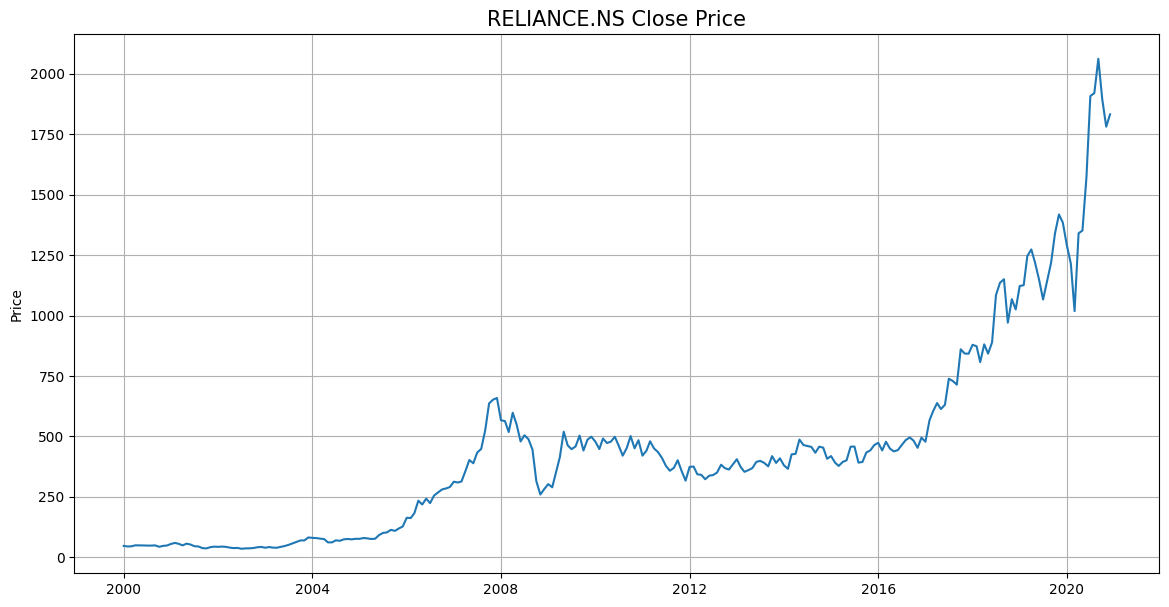

In [9]:
df = pd.DataFrame(data)

# Convert 'Date' column to datetime format, specifying the format
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

# Set the 'Date' column as the index
df.set_index('Date', inplace=True)

# Plot the data
plt.figure(figsize=(14, 7))
plt.plot(df['Close'])  # Adding markers to visualize the data points
plt.title('RELIANCE.NS Close Price', fontsize=15)
plt.ylabel('Price')
plt.grid(True)
plt.show()

In [10]:
#graph for closing and opening price together (for comparison)

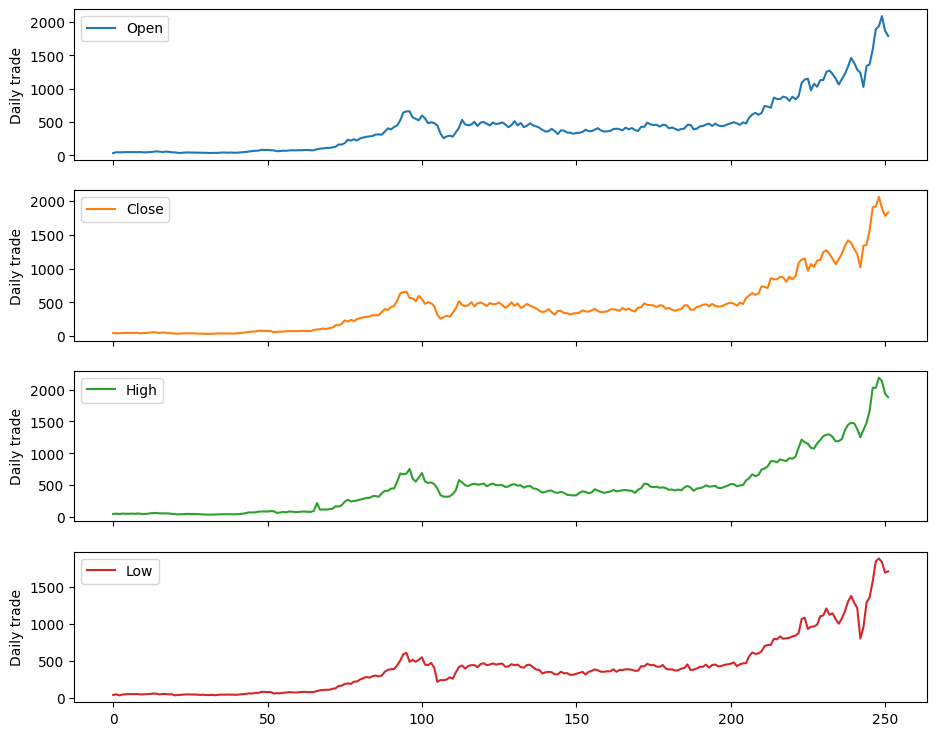

In [11]:
#open, close, high, low prices
cols_plot = ['Open', 'Close', 'High','Low']
axes = data[cols_plot].plot(figsize=(11, 9), subplots=True)
for ax in axes:
    ax.set_ylabel('Daily trade')

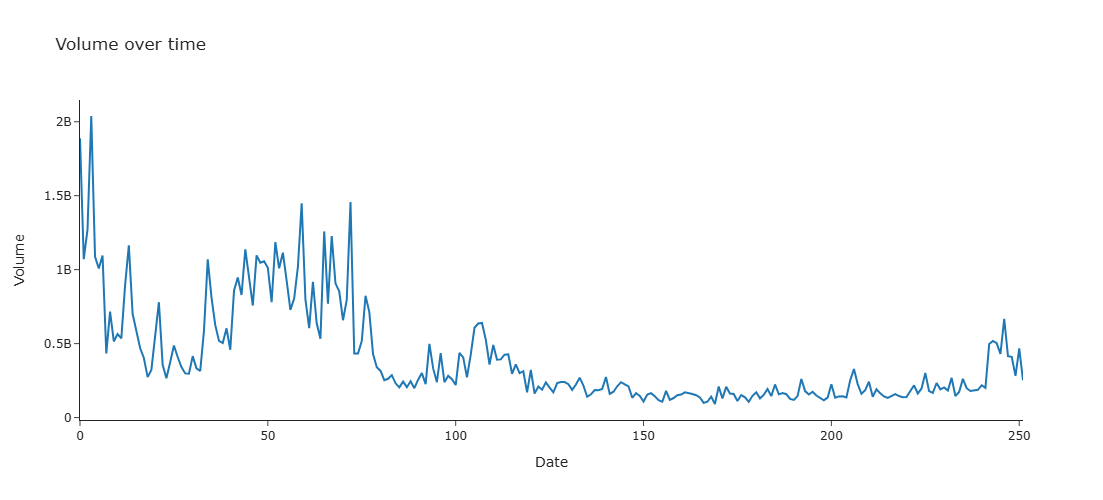

In [12]:
fig = go.Figure([go.Scatter(x=data.index, y=data['Volume'])])
fig.update_layout(
    autosize=False,
    width=950,
    height=500,
    template='simple_white',
    title='Volume over time'
)
fig.update_xaxes(title="Date")
fig.update_yaxes(title="Volume")
fig.show()

## Stationality

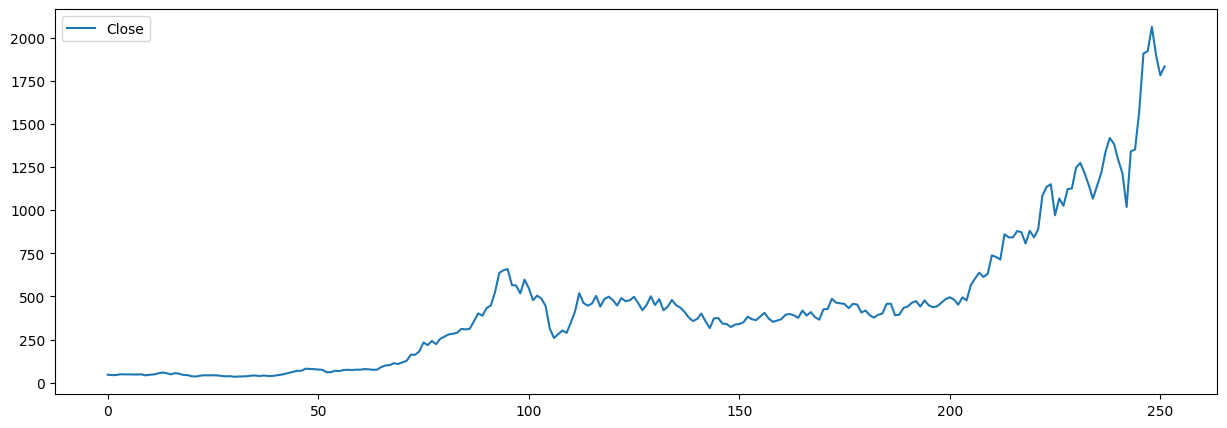

In [13]:
data_stationarity=data[['Close']]

data_stationarity.plot(figsize=(15, 5), subplots=True);

In [14]:
## From the plotted graph we can say that the data doesn't have a constant average as there are meany leaps and troughs
## and also the variance is also different at different stages of the data.
## So our data is not stationary. We can also mathematically test for stationarity with adfuller test

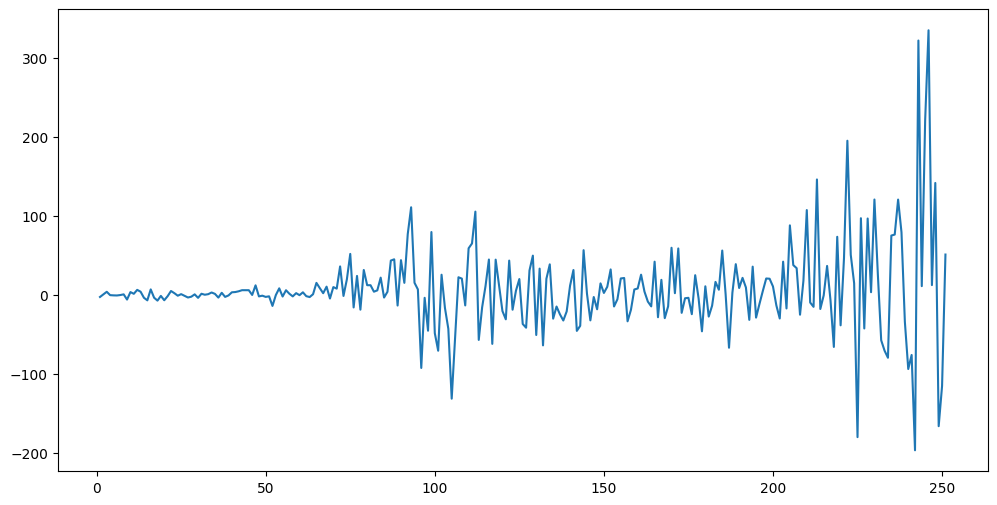

In [15]:
# coverting non-stationary data to stationary data

data_stationarity['Close First Difference']=data_stationarity['Close']-data_stationarity['Close'].shift(1)
data_stationarity['Close First Difference'].plot(figsize = (12,6));

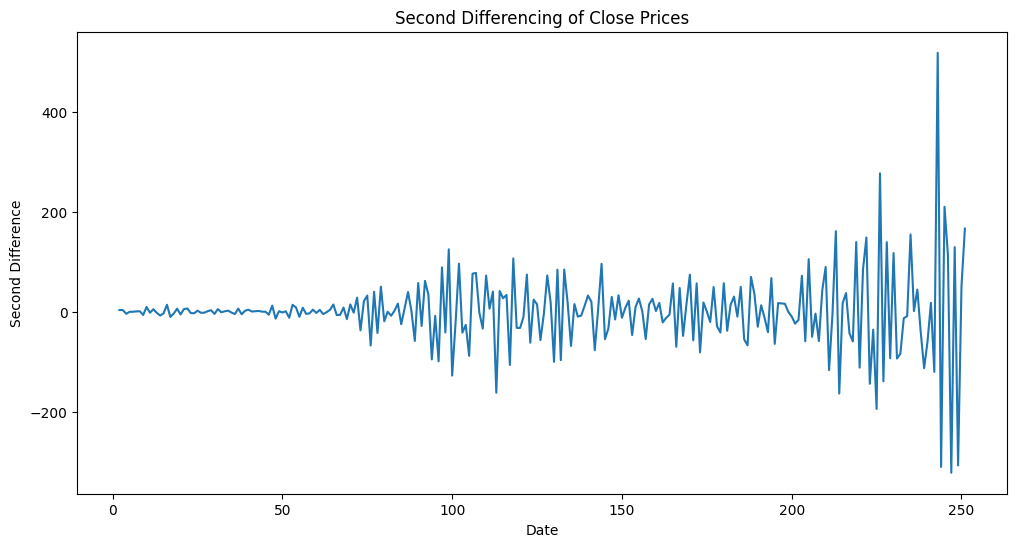

In [16]:
data_stationarity['Close Second Difference'] = data_stationarity['Close First Difference'] - data_stationarity['Close First Difference'].shift(1)

data_stationarity['Close Second Difference'].plot(figsize=(12, 6))
plt.title('Second Differencing of Close Prices')
plt.ylabel('Second Difference')
plt.xlabel('Date')
plt.show()



In [17]:
## Since we observed some fluctuations in the differenced data around 2019 so we used log transformed data 
## and used that for differencing to make sure that the data is stationary.

In [18]:
#Ho: Data is non stationary i.e, the time series has a unit root
#H1: Data is stationary i.e, the time series does not have a unit root

def adfuller_test(price):
    result=adfuller(price)
    labels = ['ADF Test Statistic','p-value','#Lags Used','Number of Observations Used']
    for value,label in zip(result,labels):
        print(label+' : '+str(value) )
    if result[1] <= 0.05:
        print("strong evidence against the null hypothesis(Ho), reject the null hypothesis. Data has no unit root and is stationary")
    else:
        print("weak evidence against null hypothesis, time series has a unit root, indicating it is non-stationary ")

In [19]:
data['BoxCox_Close'], fitted_lambda = stats.boxcox(data['Close'])

In [20]:
fitted_lambda

0.24701208420468565

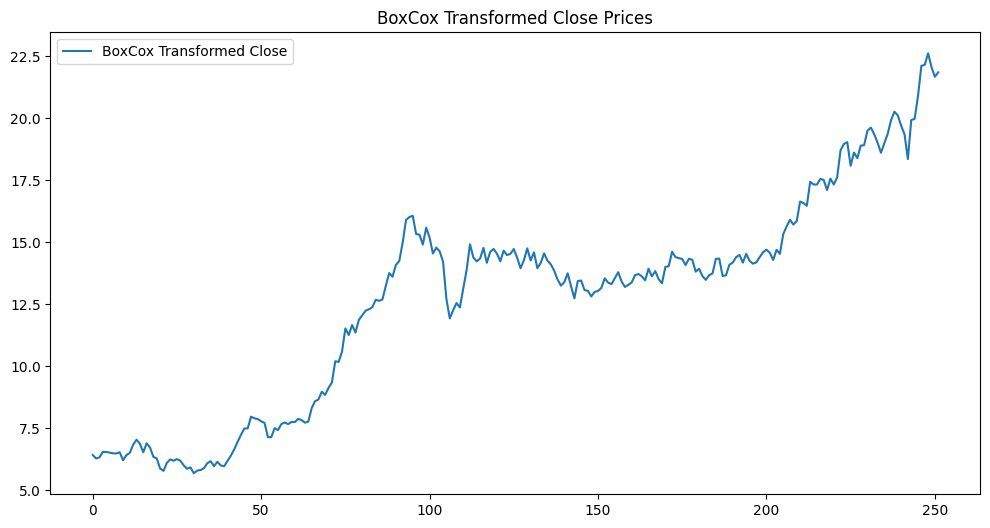

In [21]:
# Plot Log Transformed Data
plt.figure(figsize=(12, 6))
plt.plot(data['BoxCox_Close'], label='BoxCox Transformed Close')
plt.title('BoxCox Transformed Close Prices')
plt.legend()
plt.show()

In [22]:
adfuller_test(data['BoxCox_Close'])

ADF Test Statistic : 0.11249029405937612
p-value : 0.966903590411209
#Lags Used : 0
Number of Observations Used : 251
weak evidence against null hypothesis, time series has a unit root, indicating it is non-stationary 


ADF Test Statistic : -15.385486307563847
p-value : 3.363496976226922e-28
#Lags Used : 0
Number of Observations Used : 250
strong evidence against the null hypothesis(Ho), reject the null hypothesis. Data has no unit root and is stationary


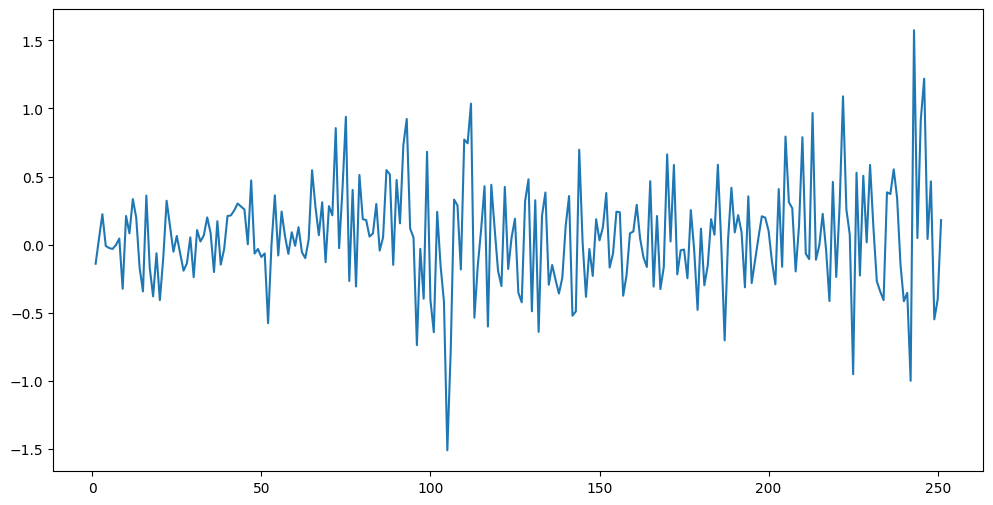

In [23]:
# Differencing
data['BoxCox_Close_Diff'] = data['BoxCox_Close'] - data['BoxCox_Close'].shift(1)
data['BoxCox_Close_Diff'].plot(figsize = (12,6))

adfuller_test(data['BoxCox_Close_Diff'].dropna())

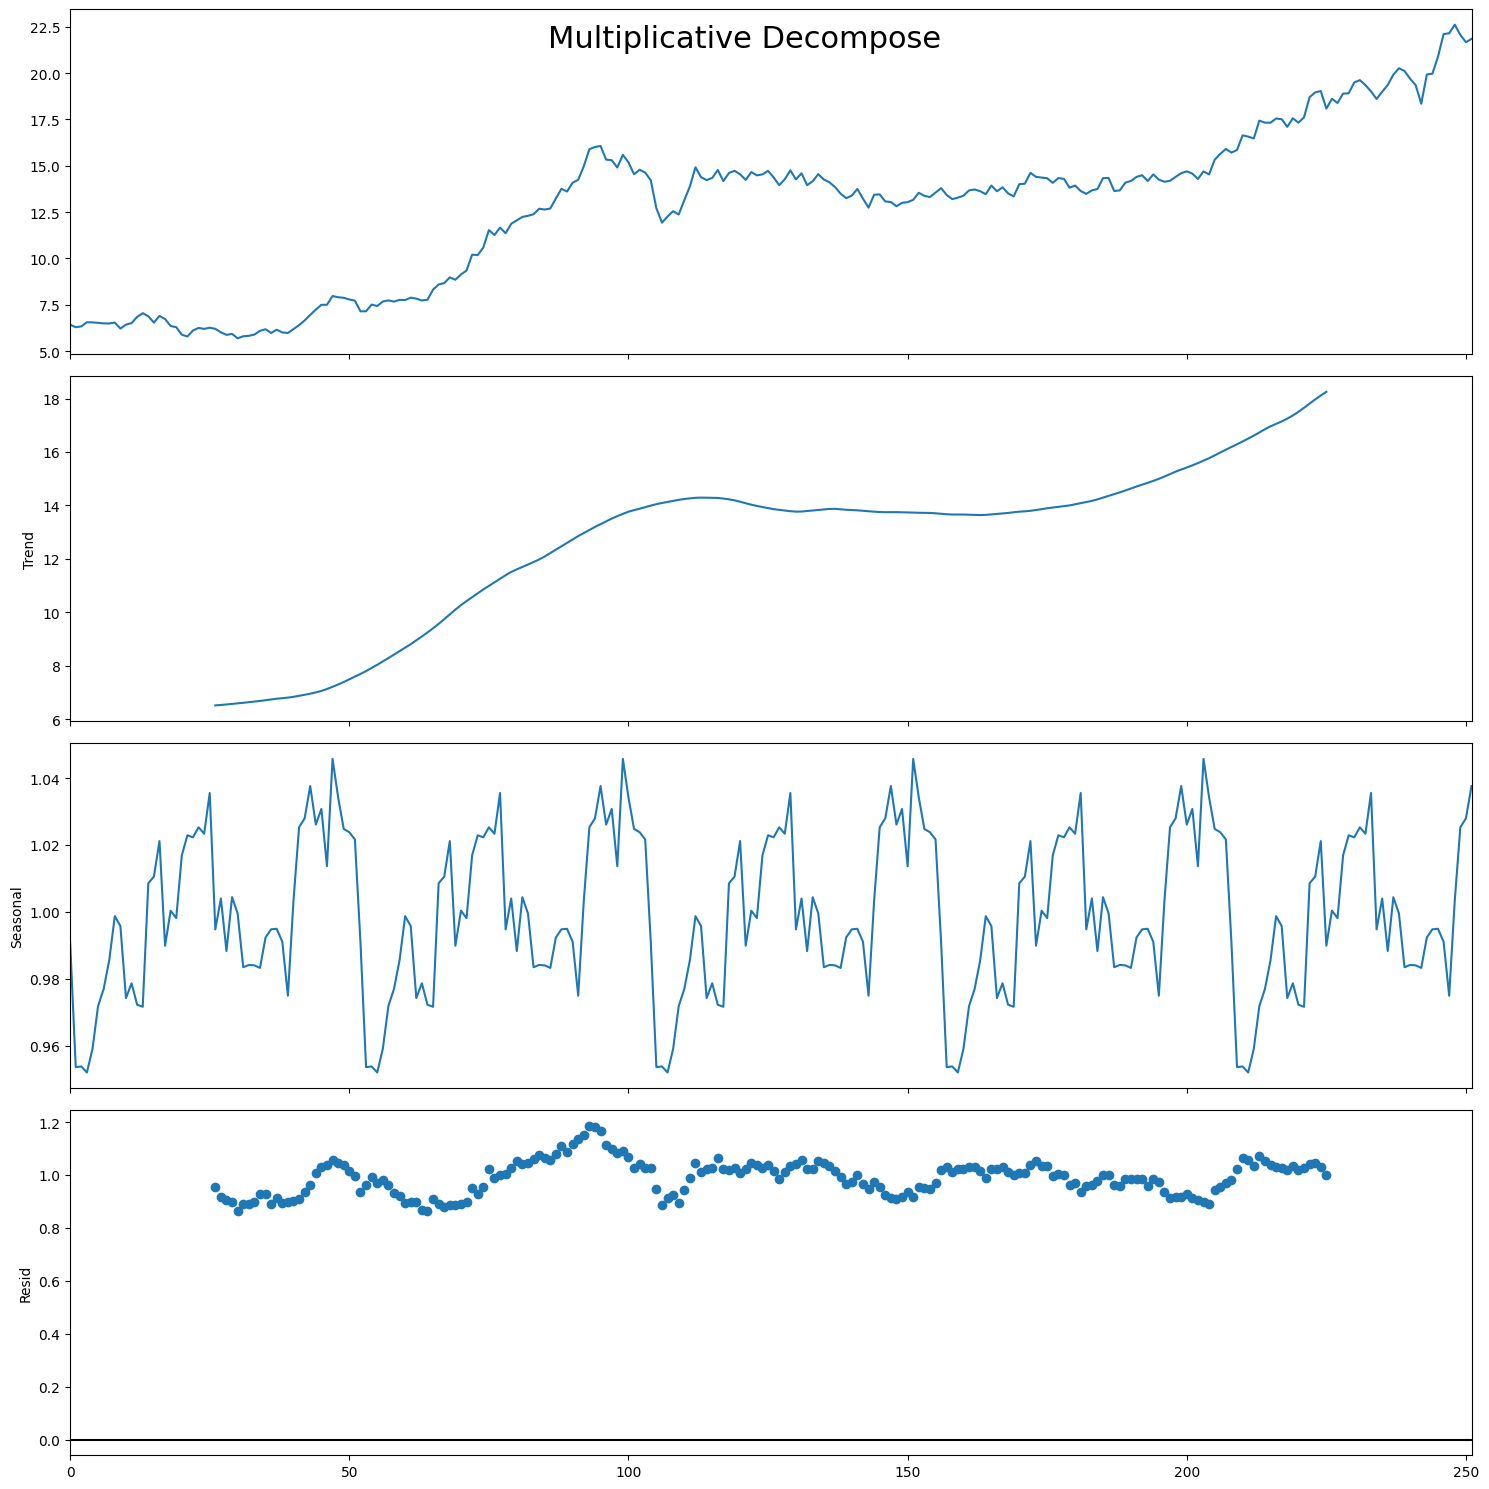

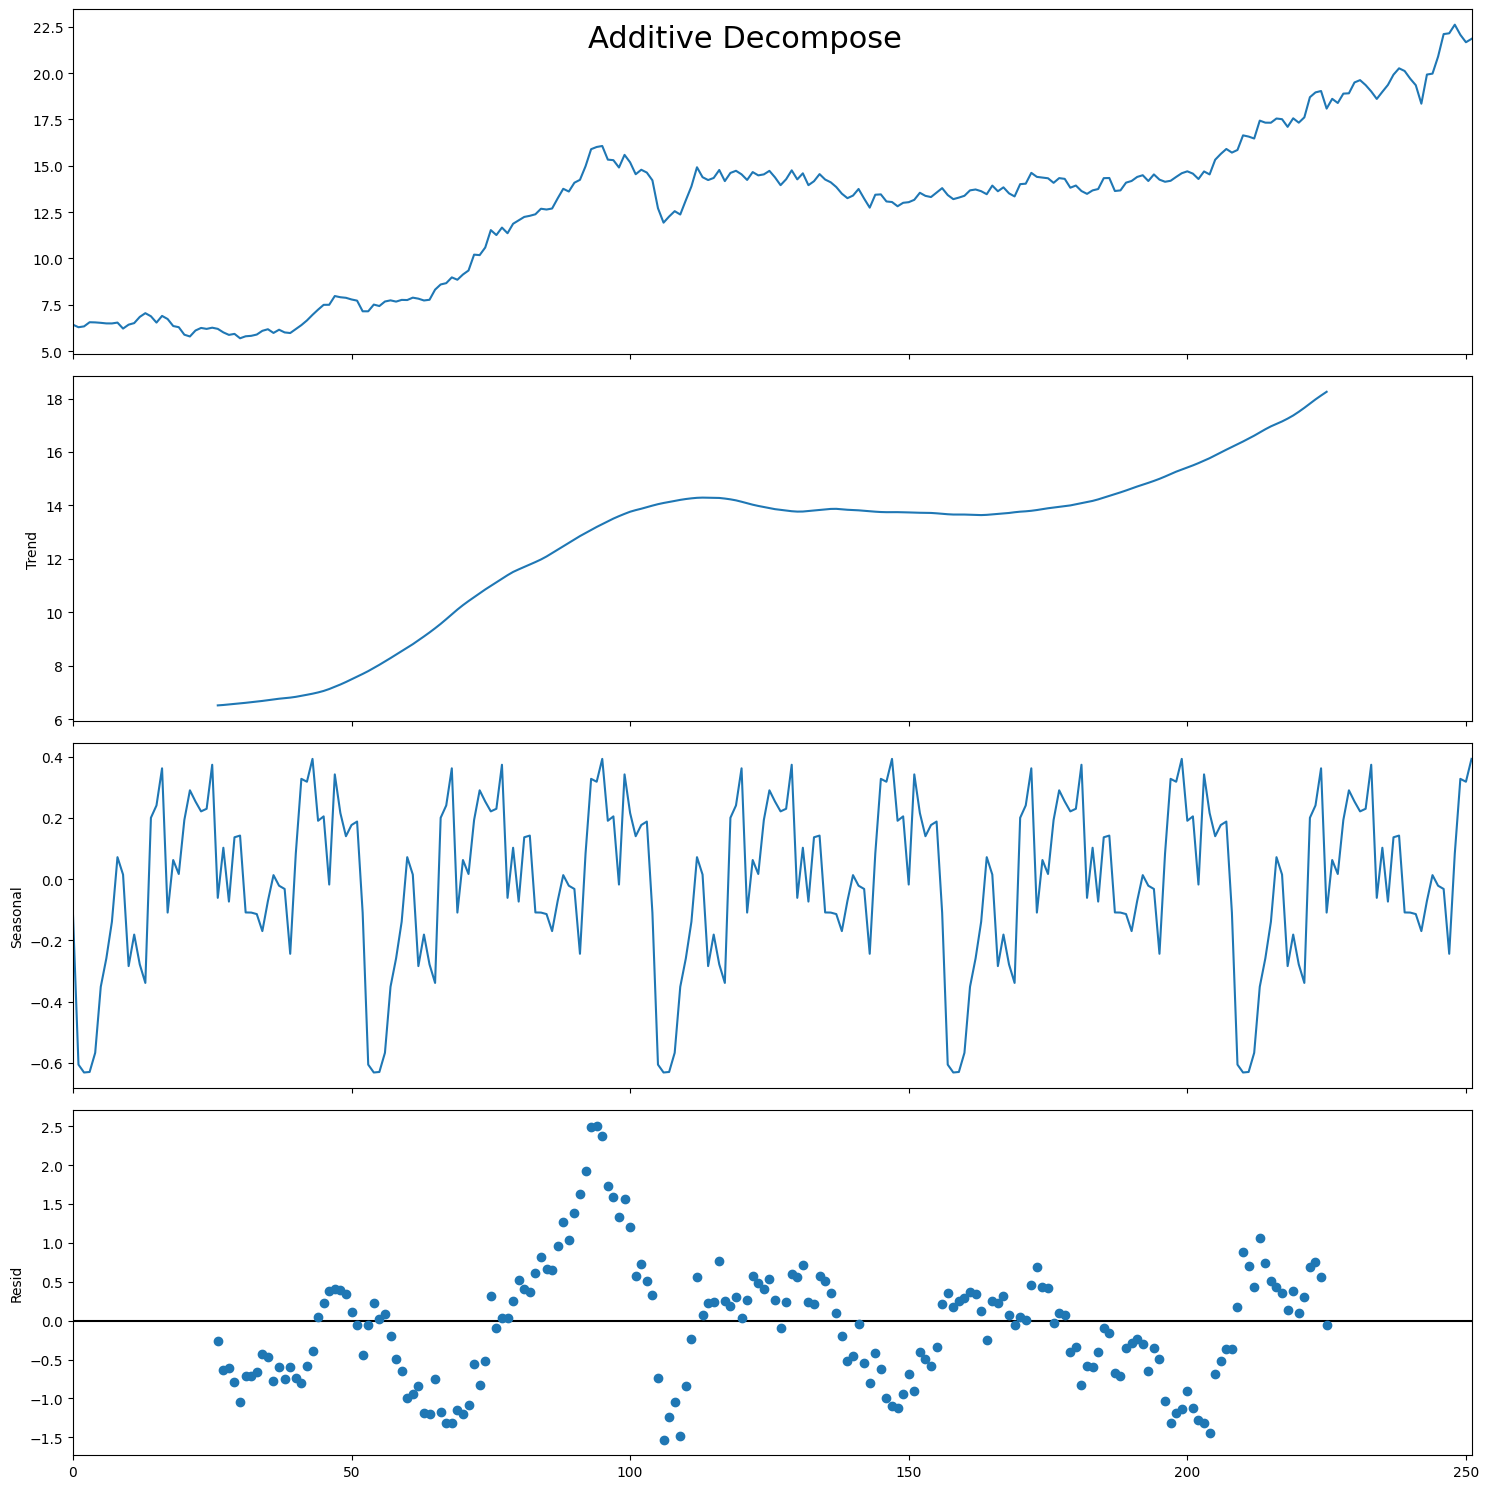

In [24]:
#seasonal decompose
plt.rcParams.update({'figure.figsize': (18,18)})
y = data['BoxCox_Close'].dropna().to_frame()


# Multiplicative Decomposition 
result_mul = seasonal_decompose(y, model='multiplicative',period = 52)

# Additive Decomposition
result_add = seasonal_decompose(y, model='additive',period = 52)

# Plot
plt.rcParams.update({'figure.figsize': (15,15)})
result_mul.plot().suptitle('Multiplicative Decompose', fontsize=22)
result_add.plot().suptitle('Additive Decompose', fontsize=22)
plt.show()

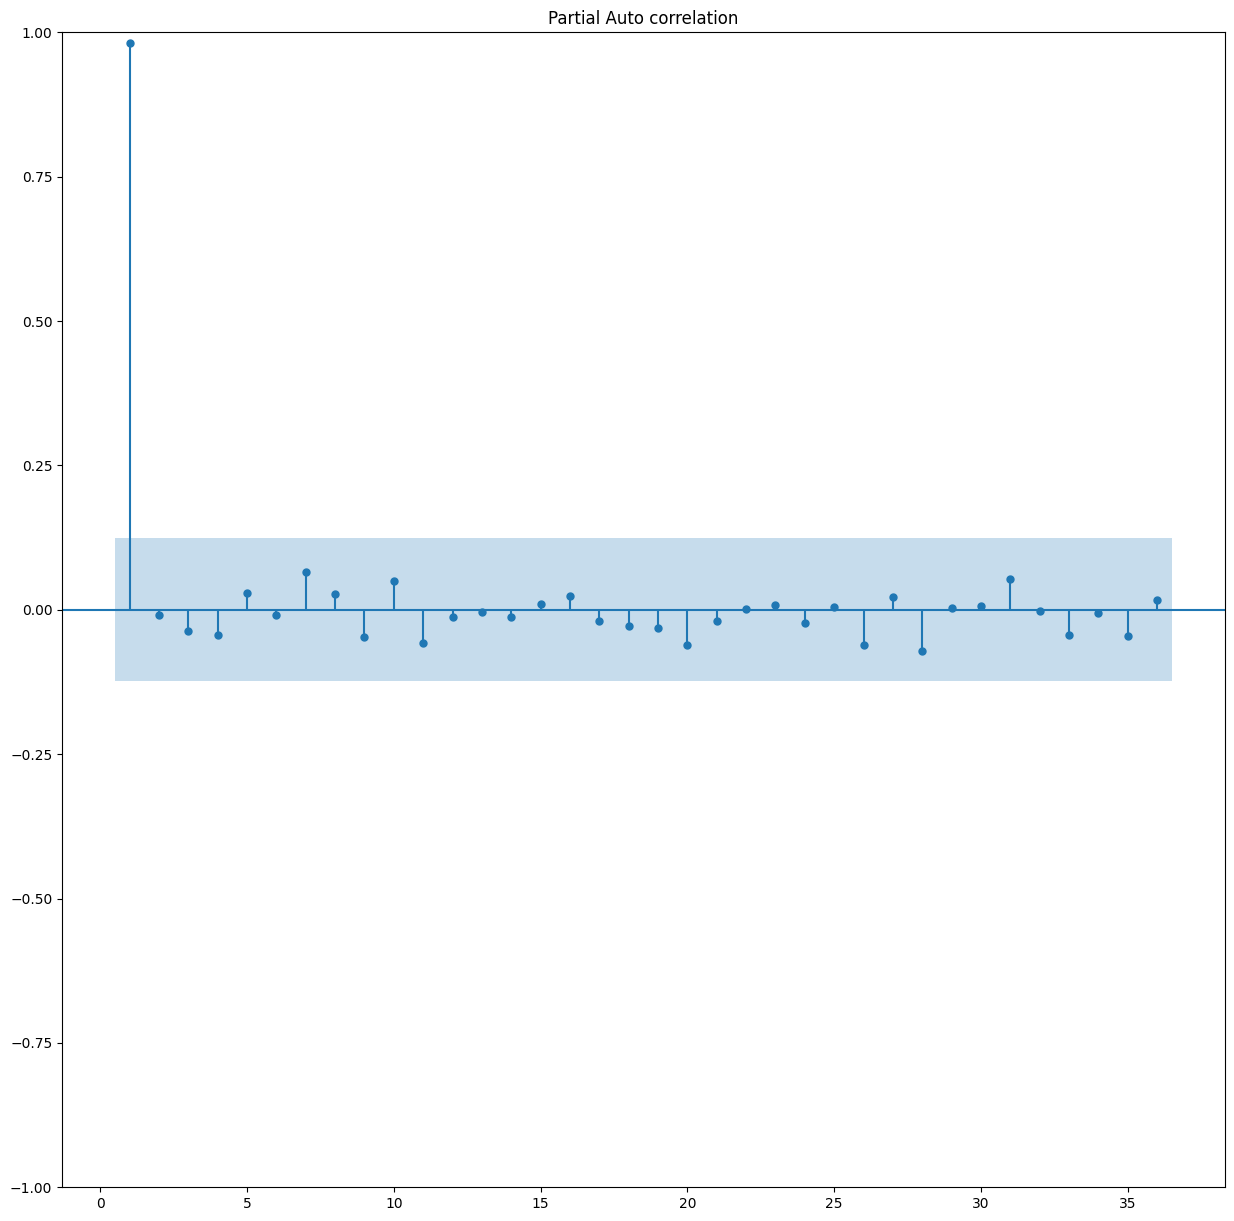

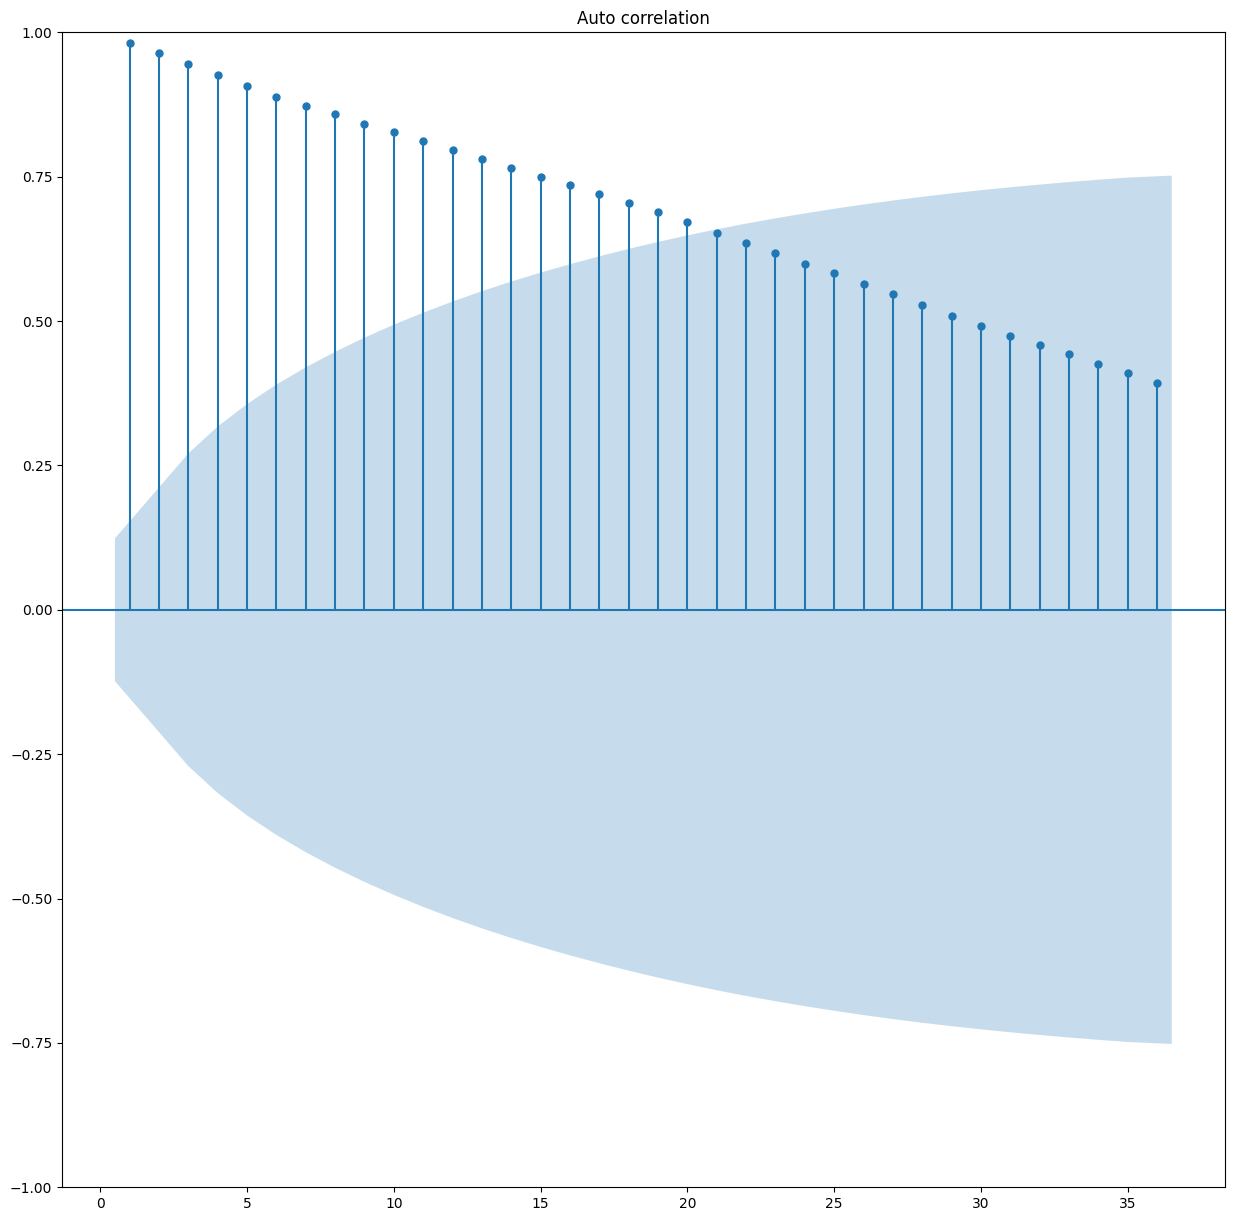

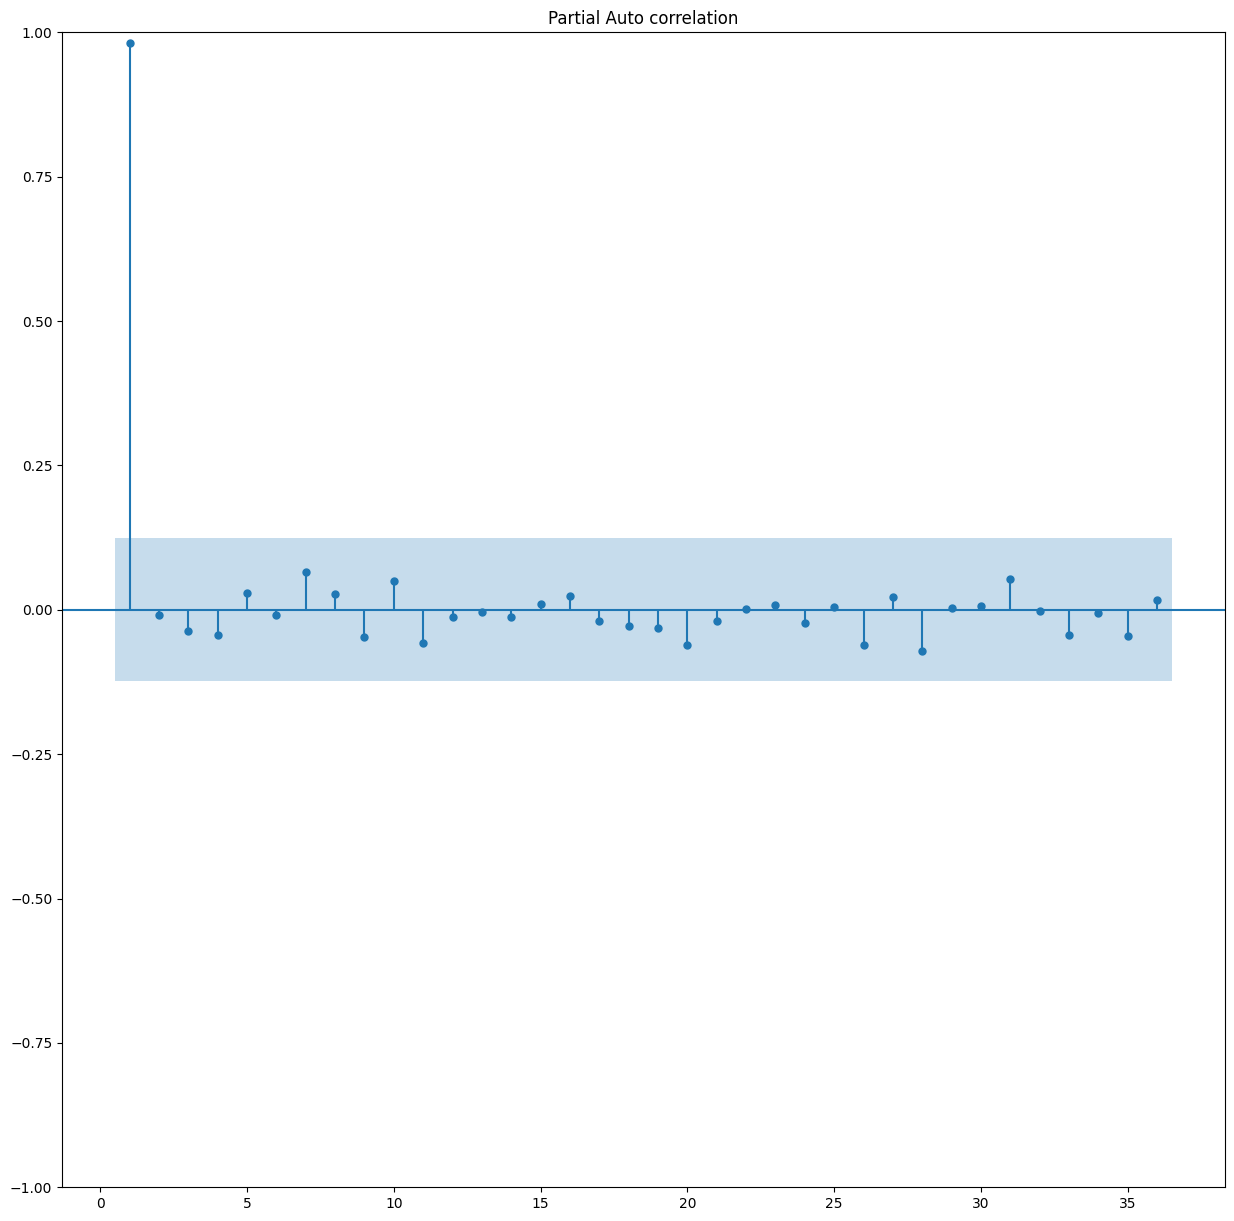

In [25]:
sm.graphics.tsa.plot_acf(data['BoxCox_Close'].iloc[1:], lags=36, title='Auto correlation', zero=False)
sm.graphics.tsa.plot_pacf(data['BoxCox_Close'].iloc[1:], lags=36, title='Partial Auto correlation', zero=False)


In [26]:
data = data.reset_index()

In [27]:
data_lr= data.copy().dropna()
data_lr.drop('Date', axis = 1, inplace = True)
X = data_lr.drop('BoxCox_Close_Diff', axis=1)
y = data_lr['BoxCox_Close_Diff']

# Drop rows with any NaN values
X = X.dropna()
y = y[X.index]  # Align the target variable with the updated X

# Now split the data and train the model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [28]:
np.isnan(X.values.any())

False

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

preds = model.predict(X_test)
mae = mean_absolute_error(y_test, preds)
mse = mean_squared_error(y_test, preds)
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)

Mean Absolute Error: 0.1482708422536171
Mean Squared Error: 0.07249396648017964


In [30]:
data.set_index("Date", drop=False, inplace=True)
data.head()

,index,Date,Open,High,Low,Close,Adj Close,Volume,Typical_Price,VWAP,BoxCox_Close,BoxCox_Close_Diff
Date,,,,,,,,,,,,
01-01-2000,0,01-01-2000,33.917892,48.827484,33.917892,46.863815,34.789986,1888178089,43.203064,43.203064,6.422874,NaN
01-02-2000,1,01-02-2000,47.242268,53.411755,43.764793,44.393166,32.955864,1070752379,47.189905,44.645787,6.283720,-0.139154
01-03-2000,2,01-03-2000,44.985836,47.106598,28.155420,45.192913,33.549568,1270823262,40.151644,43.295529,6.329388,0.045669
01-04-2000,3,01-04-2000,46.792412,54.268627,39.737488,49.277344,36.581703,2038648290,47.761153,44.747866,6.553574,0.224186
01-05-2000,4,01-05-2000,49.277344,50.955387,43.771935,49.113110,37.316151,1088031457,47.946811,45.220997,6.544835,-0.008739


Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.02 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=2110.026, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=2112.025, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=2112.025, Time=0.08 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=2110.807, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=2114.024, Time=0.13 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0] intercept
Total fit time: 1.307 seconds


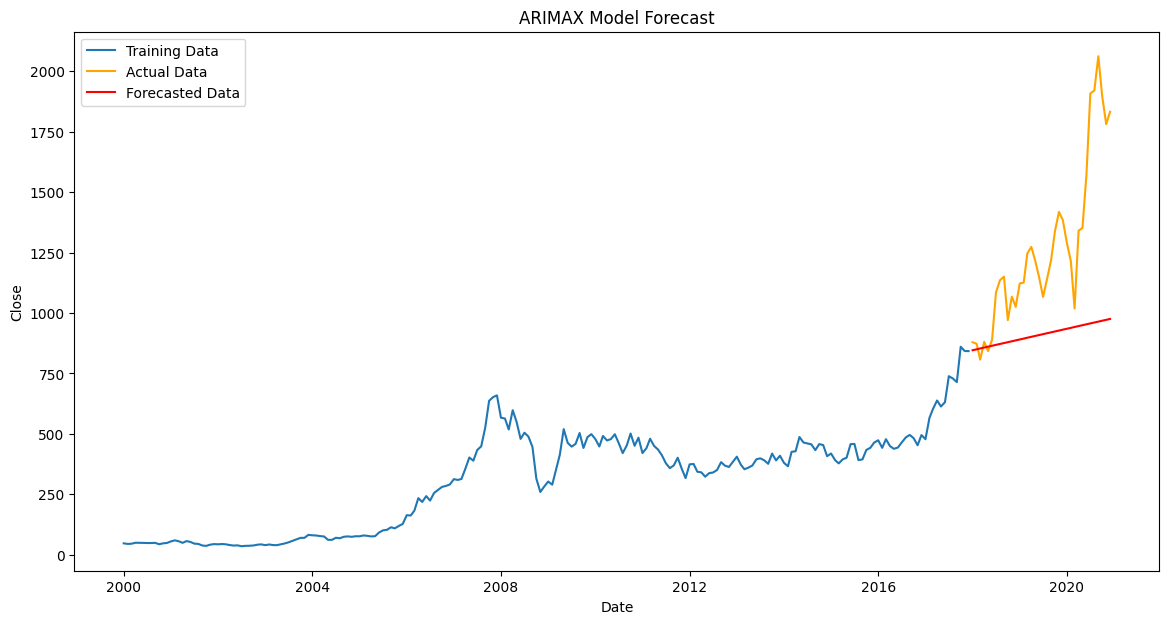

In [32]:
import pandas as pd
import numpy as np
from pmdarima import auto_arima
import matplotlib.pyplot as plt
# Convert 'Date' to datetime format, specifying the format if necessary
data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')

# Set 'Date' as the index
data.set_index('Date', inplace=True)

# Apply Box-Cox transformation to the 'Close' column (for stationarity)
from scipy.stats import boxcox
data['BoxCox_Close'], _ = boxcox(data['Close'].dropna())

# Define the training and testing periods
train_data = data.loc[:'2017-12']
test_data = data.loc['2018-01':]

# Specify the exogenous features
exogenous_features = ["Open", "High", "Low", "Volume"]

# Fit the ARIMAX model with exogenous variables
model = auto_arima(train_data['Close'].dropna(), exogenous=train_data[exogenous_features], 
                   trace=True, error_action='ignore', suppress_warnings=True)

# Forecast the future values
forecast = model.predict(n_periods=len(test_data), exogenous=test_data[exogenous_features])

# Add the forecast to the test data
test_data['Forecast_ARIMAX'] = forecast

# Plot the actual vs forecast
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Close'], label='Training Data')
plt.plot(test_data.index, test_data['Close'], label='Actual Data', color='orange')
plt.plot(test_data.index, test_data['Forecast_ARIMAX'], label='Forecasted Data', color='red')
plt.title('ARIMAX Model Forecast')
plt.xlabel('Date')
plt.ylabel('Close')
plt.legend()
plt.show()


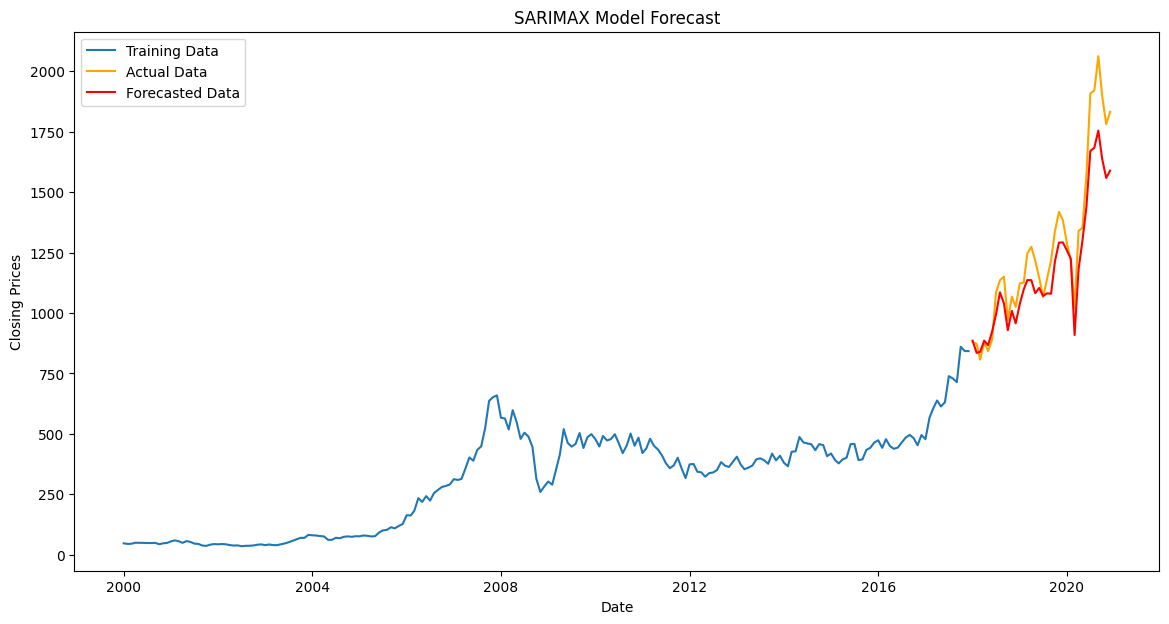

Mean Squared Error: 1386273.4337615715


In [34]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

data = pd.read_csv("RELIANCE.NS Prediction.csv")
# Convert 'Date' to datetime format
data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')

# Set 'Date' as the index
data.set_index('Date', inplace=True)

# Apply Box-Cox transformation to the 'Close' column (for stationarity)
from scipy.stats import boxcox
data['BoxCox_Close'], _ = boxcox(data['Close'].dropna())

# Define the training and testing periods
train_data = data.loc[:'2017-12']
test_data = data.loc['2018-01':]

# Specify the exogenous features
exogenous_features = ["Open", "High", "Low", "Volume"]

# SARIMAX model configuration (p, d, q)(P, D, Q, s)
# p, d, q: Non-seasonal ARIMA orders
# P, D, Q: Seasonal ARIMA orders
# s: Seasonal period (e.g., 12 for monthly data with yearly seasonality)
sarimax_model = SARIMAX(train_data['Close'],
                        exog=train_data[exogenous_features],
                        order=(1, 1, 1),            # Replace with your optimized values
                        seasonal_order=(1, 1, 1, 12), # Replace with your optimized values
                        enforce_stationarity=False,
                        enforce_invertibility=False)

# Fit the model
sarimax_fit = sarimax_model.fit(disp=False)

# Forecast the future values
forecast = sarimax_fit.forecast(steps=len(test_data), exog=test_data[exogenous_features])

# Add the forecast to the test data
test_data['Forecast_SARIMAX'] = forecast

# Plot the actual vs forecast
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Close'], label='Training Data')
plt.plot(test_data.index, test_data['Close'], label='Actual Data', color='orange')
plt.plot(test_data.index, test_data['Forecast_SARIMAX'], label='Forecasted Data', color='red')
plt.title('SARIMAX Model Forecast')
plt.xlabel('Date')
plt.ylabel('Closing Prices')
plt.legend()
plt.show()

# Evaluate the model
mse = mean_squared_error(test_data['BoxCox_Close'], test_data['Forecast_SARIMAX'])
print(f"Mean Squared Error: {mse}")

In [35]:
##Remove moving average method. Use Holt winters exponential smoothing method on original data.
## Do double/triple exponential method on original data
##Fit SARIMA instead of ARIMA
## Instead of log use Box Cox test and do its differencing. Use differenced data to plot ACF and PACF and to fit the model.

Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


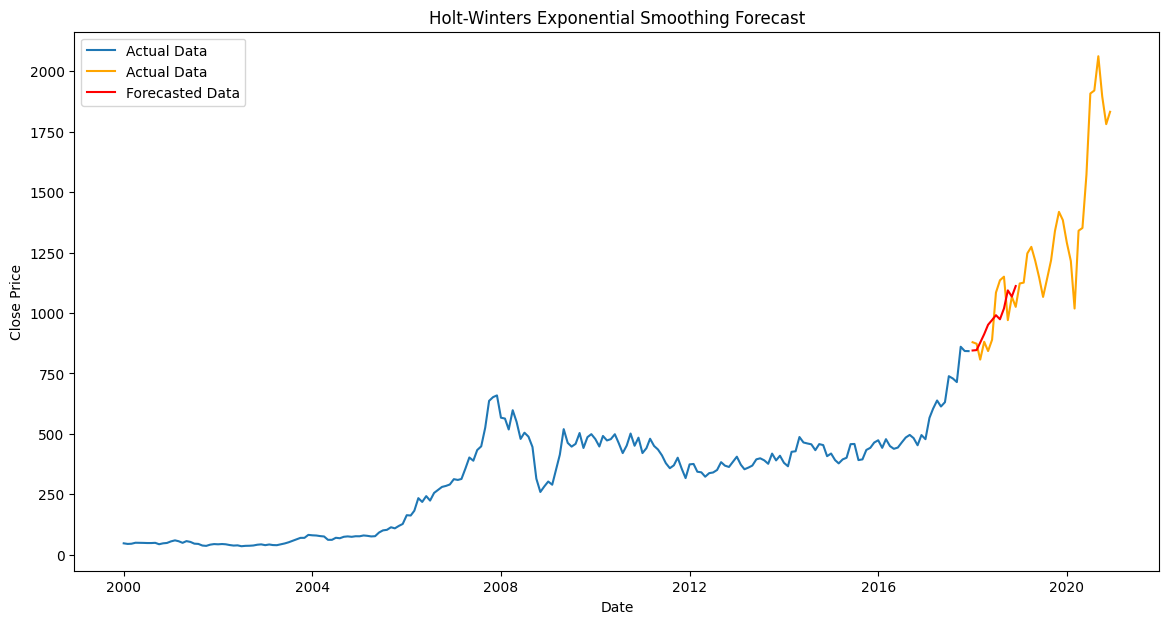

2018-01-01     844.781503
2018-02-01     846.365955
2018-03-01     877.298469
2018-04-01     912.506704
2018-05-01     951.233597
2018-06-01     970.855235
2018-07-01     990.836373
2018-08-01     973.974822
2018-09-01    1018.479550
2018-10-01    1093.416186
2018-11-01    1067.705391
2018-12-01    1111.362799
Freq: MS, dtype: float64


In [38]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
data = pd.read_csv("RELIANCE.NS Prediction.csv")

data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')

# Set 'Date' as the index
data.set_index('Date', inplace=True)
# Define the training and testing periods
train_data = data.loc[:'2017-12']
test_data = data.loc['2018-01':]

# Check for any missing values
print(data.isna().sum())

# Ensure 'Close' is numeric
train_data['Close'] = pd.to_numeric(train_data['Close'], errors='coerce')

# Drop any rows with missing values
data.dropna(inplace=True)

# Apply Holt-Winters Exponential Smoothing with multiplicative model
model = ExponentialSmoothing(train_data['Close'], trend='mul', seasonal='mul', seasonal_periods=12)
hw_fit = model.fit()

# Forecast future values (e.g., forecast 12 periods ahead)
forecast = hw_fit.forecast(steps=12)
test_data['Forecast_HW'] = forecast

# Plot the actual vs forecast
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Close'], label='Actual Data')
plt.plot(test_data.index, test_data['Close'], label='Actual Data', color='orange')
plt.plot(test_data.index, test_data['Forecast_HW'], label='Forecasted Data', color='red')
plt.title('Holt-Winters Exponential Smoothing Forecast')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()

# Print forecasted values
print(forecast)

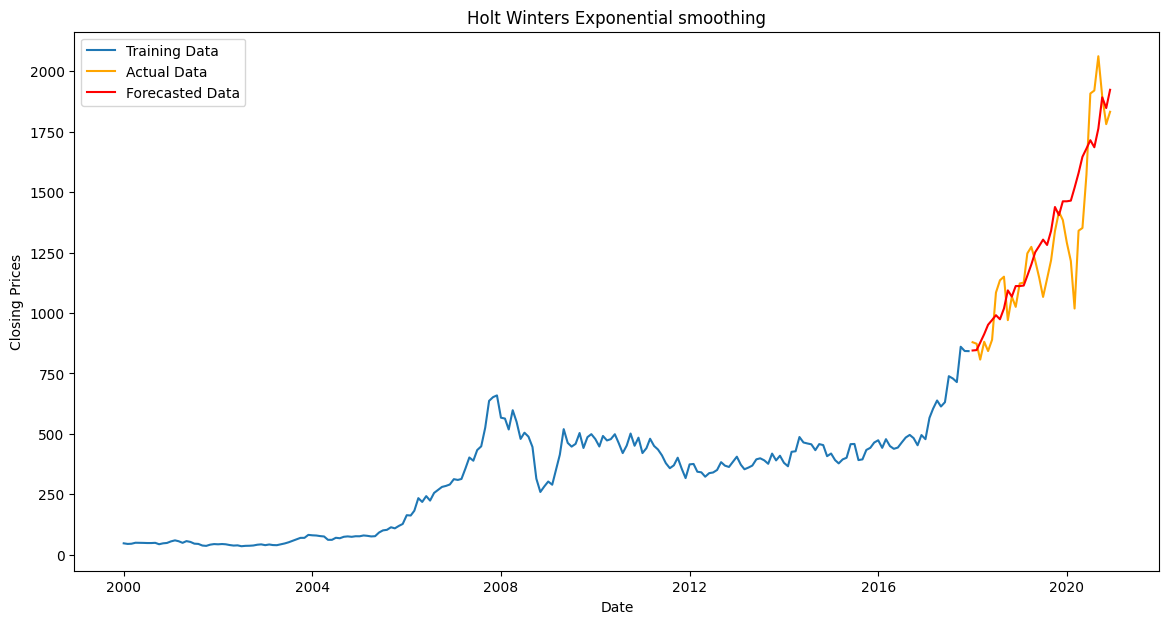

In [39]:


data = pd.read_csv("RELIANCE.NS Prediction.csv")
# Convert 'Date' to datetime format
data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')

# Set 'Date' as the index
data.set_index('Date', inplace=True)
train_data = data.loc[:'2017-12']
test_data = data.loc['2018-01':]

model = ExponentialSmoothing(train_data['Close'], trend='mul', seasonal='mul', seasonal_periods=12)
hw_fit = model.fit()

# Forecast future values (e.g., forecast 12 periods ahead)
forecast = hw_fit.forecast(steps=len(test_data))
test_data['Forecast_HW'] = forecast

# Plot the actual vs forecast
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Close'], label='Training Data')
plt.plot(test_data.index, test_data['Close'], label='Actual Data', color='orange')
plt.plot(test_data.index, test_data['Forecast_HW'], label='Forecasted Data', color='red')
plt.title('Holt Winters Exponential smoothing')
plt.xlabel('Date')
plt.ylabel('Closing Prices')
plt.legend()
plt.show()



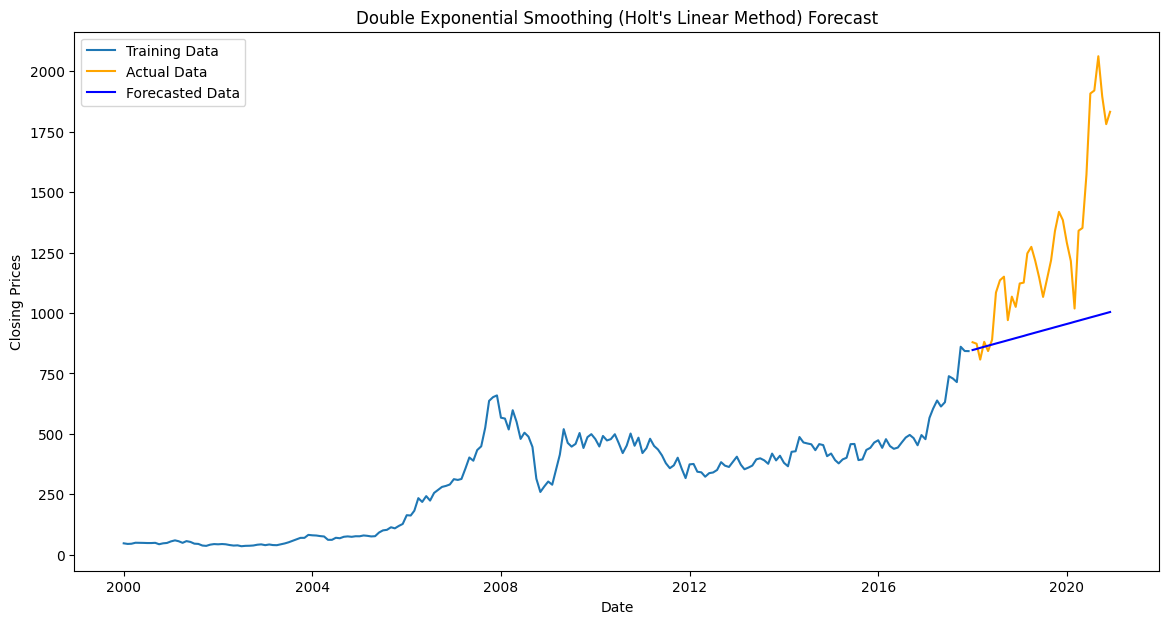

Mean Squared Error: 201196.28946690066


In [40]:
data = pd.read_csv("RELIANCE.NS Prediction.csv")

data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y')
data.set_index('Date', inplace=True)
data['Close'] = pd.to_numeric(data['Close'], errors='coerce')
data.dropna(inplace=True)

# Split the data into training and testing sets
train_data = data[:'2017-12']
test_data = data['2018-01':]

# Apply Double Exponential Smoothing (Holt's Linear Method)
model_double = ExponentialSmoothing(train_data['Close'], trend='add', seasonal=None)
fit_double = model_double.fit()

# Forecast future values starting from 2018-01
forecast_double = fit_double.forecast(steps=len(test_data))

# Add the forecast to the test data
test_data['Forecast_Double'] = forecast_double

# Plot the actual vs forecast
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Close'], label='Training Data')
plt.plot(test_data.index, test_data['Close'], label='Actual Data', color='orange')
plt.plot(test_data.index, test_data['Forecast_Double'], label='Forecasted Data', color='blue')
plt.title('Double Exponential Smoothing (Holt\'s Linear Method) Forecast')
plt.xlabel('Date')
plt.ylabel('Closing Prices')
plt.legend()
plt.show()

# Evaluate the model
mse = mean_squared_error(test_data['Close'], test_data['Forecast_Double'])
print(f"Mean Squared Error: {mse}")

New best model found: SARIMAX(0, 0, 0)x(0, 0, 0, 12) with AIC=2711.669950050995, BIC=2728.523140191633
New best model found: SARIMAX(0, 0, 0)x(0, 0, 1, 12) with AIC=1686.5238174762803, BIC=1706.403053350531
New best model found: SARIMAX(0, 0, 0)x(0, 0, 2, 12) with AIC=1601.5373528172336, BIC=1624.30326681356
New best model found: SARIMAX(0, 0, 0)x(0, 1, 2, 12) with AIC=1545.8729203329158, BIC=1568.184620973801
New best model found: SARIMAX(0, 0, 0)x(1, 1, 2, 12) with AIC=1540.06334942566, BIC=1565.562435872386
New best model found: SARIMAX(0, 0, 2)x(0, 1, 2, 12) with AIC=1538.7662592057784, BIC=1567.3516067989428
New best model found: SARIMAX(0, 0, 2)x(1, 1, 2, 12) with AIC=1538.5382167943937, BIC=1570.299714120132
New best model found: SARIMAX(2, 0, 2)x(1, 1, 2, 12) with AIC=1538.4865145372364, BIC=1576.6003113281224


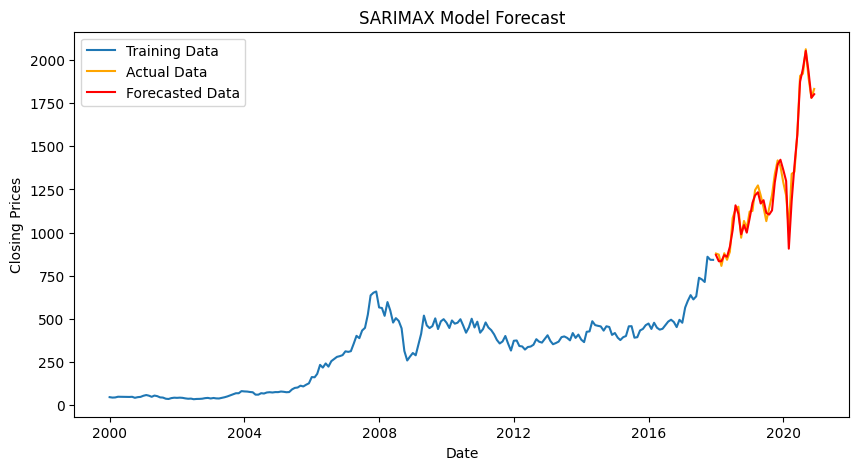

Root Mean Squared Error: 50.8961772038386


In [41]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Define the training and testing periods
train_data = data.loc[:'2017-12']
test_data = data.loc['2018-01':]

# Specify the exogenous features
exogenous_features = ["Open", "High", "Low", "Volume"]

def fit_sarimax_model(train_endog, train_exog, order, seasonal_order):
    """
    Fit a SARIMAX model and return the model, AIC, and BIC.
    """
    try:
        model = SARIMAX(train_endog,
                        exog=train_exog,
                        order=order,
                        seasonal_order=seasonal_order,
                        enforce_stationarity=False,
                        enforce_invertibility=False)
        model_fit = model.fit(disp=False)
        return model_fit, model_fit.aic, model_fit.bic
    except Exception as e:
        print(f"Error fitting SARIMAX model with order {order} and seasonal order {seasonal_order}: {e}")
        return None, np.inf, np.inf

def grid_search_sarimax(train_endog, train_exog, p_range, d_range, q_range, P_range, D_range, Q_range, s):
    """
    Perform grid search to find the best SARIMAX model based on AIC and BIC.
    """
    best_aic = np.inf
    best_bic = np.inf
    best_order = None
    best_seasonal_order = None
    best_model = None

    for p in p_range:
        for d in d_range:
            for q in q_range:
                for P in P_range:
                    for D in D_range:
                        for Q in Q_range:
                            order = (p, d, q)
                            seasonal_order = (P, D, Q, s)
                            model, aic_value, bic_value = fit_sarimax_model(train_endog, train_exog, order, seasonal_order)
                            if model and aic_value < best_aic:
                                best_aic = aic_value
                                best_bic = bic_value
                                best_order = order
                                best_seasonal_order = seasonal_order
                                best_model = model
                                print(f"New best model found: SARIMAX{order}x{seasonal_order} with AIC={aic_value}, BIC={bic_value}")

    return best_model, best_order, best_seasonal_order, best_aic, best_bic

# Perform grid search for SARIMAX model
p_range = range(0, 3)  # Adjust these ranges as needed
d_range = range(0, 2)
q_range = range(0, 3)
P_range = range(0, 3)
D_range = range(0, 2)
Q_range = range(0, 3)
s = 12  # Seasonal period (e.g., 12 for yearly seasonality in monthly data)

# Correct endogenous (target) and exogenous (features) data for the training set
train_endog = train_data['Close']  # Univariate target variable
train_exog = train_data[exogenous_features]  # Exogenous features

best_model, best_order, best_seasonal_order, best_aic, best_bic = grid_search_sarimax(
    train_endog=train_endog,  # Correct parameter name
    train_exog=train_exog,  # Correct parameter name
    p_range=p_range,
    d_range=d_range,
    q_range=q_range,
    P_range=P_range,
    D_range=D_range,
    Q_range=Q_range,
    s=s
)

# Forecast the future values using the best model
forecast = best_model.get_forecast(steps=len(test_data), exog=test_data[exogenous_features])
forecast_values = forecast.predicted_mean

# Add the forecast to the test data
test_data['Forecast_SARIMAX'] = forecast_values

# Plot the actual vs forecast
plt.figure(figsize=(10, 5))
plt.plot(train_data.index, train_data['Close'], label='Training Data')
plt.plot(test_data.index, test_data['Close'], label='Actual Data', color='orange')
plt.plot(test_data.index, test_data['Forecast_SARIMAX'], label='Forecasted Data', color='red')
plt.title('SARIMAX Model Forecast')
plt.xlabel('Date')
plt.ylabel('Closing Prices')
plt.legend()
plt.show()

# Evaluate the model
mse = mean_squared_error(test_data['Close'], test_data['Forecast_SARIMAX'])
# Calculate the Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

print(f"Root Mean Squared Error: {rmse}")
